# DL_01 — Data preparation for the deep-learning pipeline

**Purpose.** Load the supplied UJIIndoorLoc partitions, validate their schema, reproduce the
AML group split, fit the RSSI preprocessor on internal-training rows only, and build the
1,040-feature network input used by DL_02–DL_05.

**Code.** `src/signal2space_dl/data.py` (this notebook calls it; it does not re-implement it).

**Inputs.** `data/raw/trainingData.csv`, `data/raw/validationData.csv`.

**Outputs.**
- `data/processed/dl_01_split_manifest.csv` — `SOURCE_PARTITION, ROW_ID, DL_SPLIT` for all 21,048 rows
- `data/processed/dl_01_preprocessor.json` — train-fitted per-WAP mean/scale/imputation, label classes, coordinate centre
- `data/tables/dl_01_data_quality.csv`, `dl_01_split_summary.csv`, `dl_01_split_parity.json`
- `data/figures/dl_01_input_representation.png`

**Leakage rules.** The split uses only `trainingData.csv`; groups (`BUILDINGID_FLOOR_SPACEID`) never
cross internal-train/internal-validation; every fitted statistic comes from internal-train rows;
`validationData.csv` is only transformed and is reserved for the final held-out evaluation.

In [1]:
import sys
from pathlib import Path

# Locate the repository root whether Jupyter starts in the root or in "Deep Learning Pipeline/".
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "signal2space_dl").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import json, platform
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from signal2space_dl import config as C, data as D, evaluate as E, plots as P
from signal2space_dl.cli import run_compare, run_evaluate, run_train

paths = C.Paths(ROOT).ensure()
cfg = C.TrainConfig()
pd.set_option("display.width", 160, "display.max_columns", 30)
print(f"Repository: {ROOT}")
print(f"Python {platform.python_version()} | torch {torch.__version__} | pandas {pd.__version__} | NumPy {np.__version__}")

Repository: /home/user/Signal2Space
Python 3.13.18 | torch 2.15.0+cu132 | pandas 3.0.6 | NumPy 2.5.4


## 1. Load and validate the raw schema

In [2]:
train_raw, heldout_raw = D.load_raw(paths)   # raises SchemaError on any violation
print("trainingData.csv:", train_raw.shape, "| validationData.csv:", heldout_raw.shape)
print("WAP columns:", C.WAP_COLUMNS[0], "...", C.WAP_COLUMNS[-1], f"({len(C.WAP_COLUMNS)})")
print("Targets:", C.TARGET_COLUMNS, "| metadata (never used as inputs):", C.METADATA_COLUMNS)
print("Sentinel for an undetected access point:", C.MISSING_SIGNAL)
display(D.describe_quality(train_raw, heldout_raw))

trainingData.csv: (19937, 531) | validationData.csv: (1111, 531)
WAP columns: WAP001 ... WAP520 (520)
Targets: ['LONGITUDE', 'LATITUDE', 'FLOOR', 'BUILDINGID'] | metadata (never used as inputs): ['SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']
Sentinel for an undetected access point: 100


,partition,rows,duplicate_raw_rows,rows_with_zero_detected_waps,missing_signal_fraction,median_detected_waps,waps_never_detected
0,trainingData,19937,637,76,0.965395,17.0,55
1,validationData,1111,0,0,0.968317,15.0,153


The value `100` is not a signal strength: it means the access point was not detected. Detected
readings are negative dBm values. Because most WAPs are absent from any one fingerprint, the
network receives both a standardised value and an explicit presence indicator for each WAP.

## 2. Split, fit the preprocessor on internal-train, transform all partitions

In [3]:
data = D.prepare(paths, coord_scale=cfg.coord_scale, save=True)
display(pd.read_csv(paths.tables / "dl_01_split_summary.csv"))
print("Split parity with AML internal validation:", data.parity)
assert data.parity.get("identical_internal_validation_rows", True), "DL split differs from AML split"
print("Preprocessor fitted on", data.preprocessor.fit_rows, "internal-train rows")

,split,rows,n_features,building_0,building_1,building_2,floor_0,floor_1,floor_2,floor_3,floor_4
0,internal_train,16085,1040,4177,4102,7806,3569,3892,3592,4170,862
1,internal_validation,3852,1040,1072,1094,1686,800,1110,824,878,240
2,heldout_validation,1111,1040,536,307,268,132,462,306,172,39


Split parity with AML internal validation: {'checked': True, 'identical_internal_validation_rows': True, 'aml_rows': 3852, 'dl_rows': 3852}
Preprocessor fitted on 16085 internal-train rows


## 3. Inspect the fitted preprocessing

In [4]:
pre = data.preprocessor
stats = pd.DataFrame({"WAP": C.WAP_COLUMNS, "train_mean_dBm": pre.means, "train_scale_dB": pre.scales,
                      "missing_fill_z": pre.impute})
display(stats.head(8))
print("Building classes:", pre.building_classes, "| floor classes:", pre.floor_classes)
print("Coordinate centre (internal-train mean):", pre.coord_mean.round(2), "| coordinate scale:", pre.coord_scale)
for s, X in data.X.items():
    print(f"{s:20s} X shape {X.shape}  finite={np.isfinite(X).all()}  mean detected WAPs={X[:, C.N_WAPS:].sum(1).mean():.1f}")

,WAP,train_mean_dBm,train_scale_dB,missing_fill_z
0,WAP001,-95.250000,1.299038,-1.577350
1,WAP002,-89.600000,1.200000,-1.333333
2,WAP003,-78.656485,12.484147,-3.030056
3,WAP004,-78.656485,12.484147,-3.030056
4,WAP005,-92.525000,2.121173,-3.109682
5,WAP006,-85.082707,8.755273,-2.475373
6,WAP007,-81.919390,12.040239,-2.418627
7,WAP008,-81.473684,9.784530,-2.689025


Building classes: [0, 1, 2] | floor classes: [0, 1, 2, 3, 4]
Coordinate centre (internal-train mean): [  -7463.03 4864869.91] | coordinate scale: 10.0
internal_train       X shape (16085, 1040)  finite=True  mean detected WAPs=17.9
internal_validation  X shape (3852, 1040)  finite=True  mean detected WAPs=18.3
heldout_validation   X shape (1111, 1040)  finite=True  mean detected WAPs=16.5


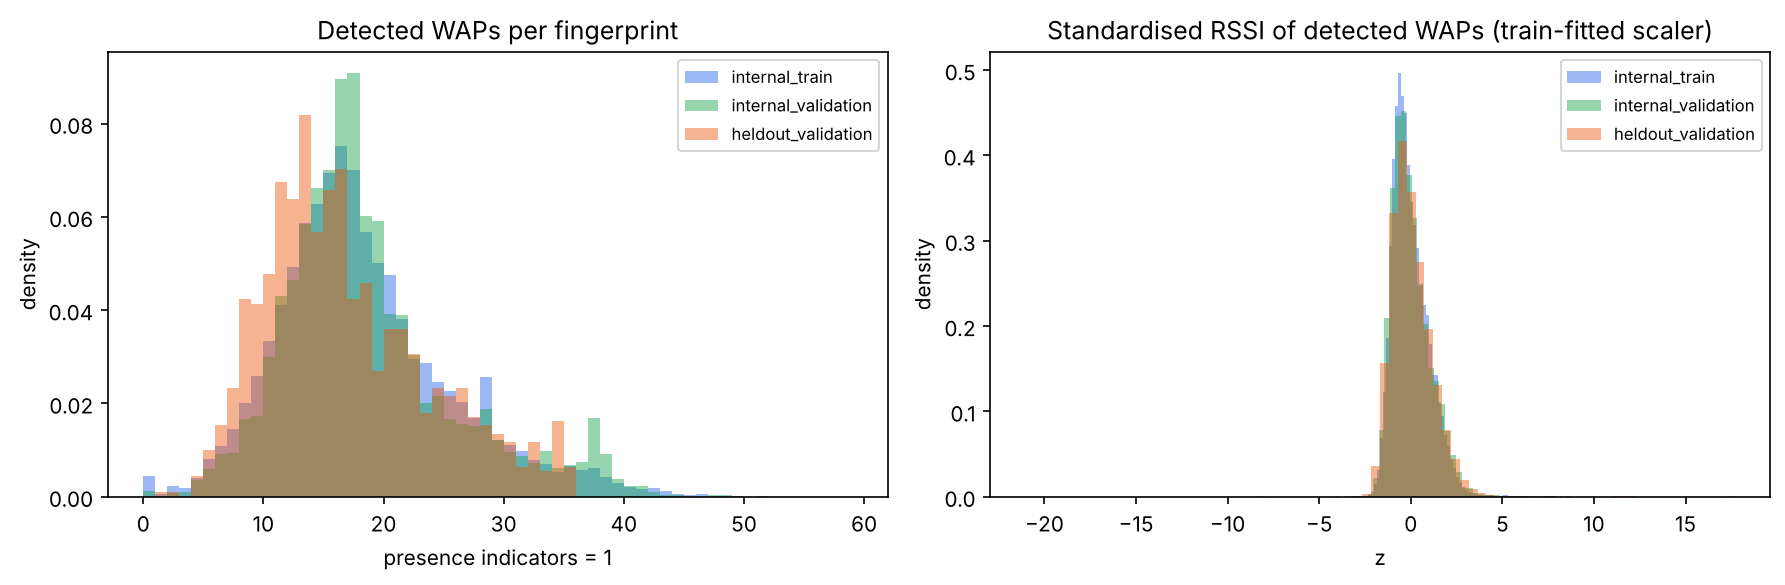

In [5]:
P.input_representation(data, paths)
display(Image(paths.figures / "dl_01_input_representation.png"))

## Handover to DL_02–DL_05

Every later notebook calls `D.prepare(paths, save=False)`, which recreates exactly these
partitions and inputs from the raw CSVs (deterministic seed 42). The manifest and preprocessor
JSON written here are the audit record of that split; the checkpoints also embed the preprocessor.

## Findings

- Both CSVs pass the schema checks: 529 columns in the verified order, no blanks, numeric dtypes, detected RSSI within [-110, 0] dBm, and `100` used only as the not-detected sentinel.
- About 96.5% of WAP entries in training (96.8% held-out) are `100`. The median fingerprint detects 17 WAPs in training and 15 in held-out. 76 training rows detect no WAP at all; they are kept, and the presence indicators let the network see that.
- The group split reproduces ML_01 exactly: 16,085 internal-train and 3,852 internal-validation rows, and the internal-validation `ROW_ID`s are identical to the AML internal-validation predictions (`dl_01_split_parity.json`).
- Floor 4 appears only in building 2: 862 internal-train rows, 240 internal-validation rows and 39 held-out rows. That makes it the smallest class.
- 55 WAPs are never detected in internal training data. They fall back to the global train statistics and carry no learned signal.